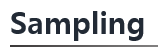

In [14]:
import numpy as np
import pandas as pd

# 임의의 데이터 생성
data = pd.DataFrame({
    'id': range(1, 101),  # 1부터 100까지의 id
    'value': np.random.rand(100)  # 임의의 값
})


In [15]:
data.head()

,id,value
0,1,0.398221
1,2,0.209844
2,3,0.186193
3,4,0.944372
4,5,0.739551


In [ ]:
# data

단순 무작위 샘플링

In [19]:
# 단순 무작위 샘플링으로 10개의 샘플 선택
sample_random = data.sample(n=5)
  # sample(...): 데이터에서 무작위(랜덤)로 표본을 추출하는 함수
  # n=5: 추출할 데이터의 개수

sample_random


,id,value
19,20,0.896671
22,23,0.663078
28,29,0.588317
83,84,0.961570
85,86,0.949319


In [28]:
# 비교 random_state = 42...
sample_random2 = data.sample(n=5, random_state = 42)

sample_random2

,id,value
83,84,0.961570
53,54,0.132068
70,71,0.240829
45,46,0.424685
44,45,0.207470


**계통** 샘플링(체계적 추출)

In [ ]:
# len(data)

In [7]:
# 계통 샘플링을 위한 간격(k) 계산
k = len(data) // 10  # ex, 전체 데이터에서 10개의 샘플을 선택하고자 할 때의 간격
                     # // 10: 10으로 나눈 뒤 소수점 아래를 버리고 정수 몫만 취하는 연산자입니다.
                     # 105 // 10 -> 10
print(k)
# 시작점을 무작위로 선택
start = np.random.randint(0, k)
# 0부터 k - 1 사이의 무작위 정수 하나를 뽑아 변수 start에 저장
# print(start)


# 계통 샘플링 실행
                        # 행의 위치 번호(정수 인덱스)를 기준으로 데이터 슬라이싱
                        # [시작위치 : 끝위치 : 간격]
sample_systematic = data.iloc[start::k] # ... 가운데 값 비어 있음 (::): 데이터의 맨 끝 행까지 모두 포함
   # iloc 데이터프레임에서 특정 행을 인덱스 기반으로 접근하는 메서드
   # start: 첫 번째로 선택할 행의 인덱스
   # k: 추출 간격 = 선택 표본 사이의 행 간격
   # ex) start=2 k=3 => data.iloc[2::3]
      # data에서 2번 인덱스에서 시작하여 3행 간격으로 데이터를 추출 즉, 2번, 5번, 8번, ... 인덱스의 행 선택

print(sample_systematic)


10
     id     value
9    10  0.434417
19   20  0.896671
29   30  0.831048
39   40  0.730856
49   50  0.586784
59   60  0.488056
69   70  0.292148
79   80  0.485628
89   90  0.874288
99  100  0.639473


In [13]:
len(data)

10

군집 샘플링

In [9]:
import pandas as pd
import numpy as np

# 가상의 데이터 생성
np.random.seed(0)  # 재현 가능한 결과를 위한 시드 설정
data = pd.DataFrame({
    'id': range(1, 101),
    'value': np.random.rand(100),
    'cluster': np.random.choice(['A', 'B', 'C', 'D', 'E'], 100)  # 군집 A, B, C, D, E 중 하나를 무작위로 할당
})

# 군집별로 데이터 확인
print(data['cluster'].value_counts())

# 군집 선택: ex 무작위로 2개의 군집을 선택
selected_clusters = np.random.choice(['A', 'B', 'C', 'D', 'E'], 2, replace=False)
print("Selected Clusters:", selected_clusters)

# 선택된 군집의 데이터만 추출
sampled_data = data[data['cluster'].isin(selected_clusters)]
print(sampled_data)


cluster
D    27
A    27
B    17
C    15
E    14
Name: count, dtype: int64
Selected Clusters: ['B' 'C']
    id     value cluster
0    1  0.548814       C
2    3  0.602763       C
9   10  0.383442       C
10  11  0.791725       C
20  21  0.978618       B
25  26  0.639921       B
28  29  0.521848       B
30  31  0.264556       B
36  37  0.612096       B
39  40  0.681820       B
40  41  0.359508       C
43  44  0.060225       B
44  45  0.666767       B
49  50  0.363711       C
51  52  0.438602       C
59  60  0.244426       C
63  64  0.138183       C
66  67  0.820993       B
71  72  0.468651       B
72  73  0.976761       B
73  74  0.604846       B
75  76  0.039188       C
76  77  0.282807       C
79  80  0.118728       B
80  81  0.317983       C
82  83  0.064147       B
84  85  0.566601       C
85  86  0.265389       C
87  88  0.093941       B
92  93  0.131798       C
95  96  0.183191       B
96  97  0.586513       B


**부트스트랩 샘플링**

In [10]:
import numpy as np

# 원본 데이터 (모집단)
data = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

# 부트스트랩 샘플링 (복원 추출, 크기는 원본과 동일)
                   # 배열이나 리스트 중 요소를 무작위로 선택하는 함수
bootstrap_sample = np.random.choice(data, size=len(data), replace=True)
   # replace=True: 복원 추출 (같은 데이터 여러 번 선택 가능)
   #

print("원본 데이터:", data)
print("부트스트랩 샘플:", bootstrap_sample)


### 부트스트랩(Bootstrap) 샘플링
# 중복과 누락 발생: 100개의 데이터에서 복원 추출로 100개를 뽑으면,
  # 어떤 데이터는 중복해서 뽑히고 어떤 데이터는 한 번도 뽑히지 않을 수 있음
  # 가상의 표본 집단을 여러 개 만들어 평균이나 신뢰구간을 추정하거나,
  # 머신러닝에서 배깅(Bagging), 랜덤 포레스트(Random Forest) 모델을 학습시킬 때 사용



원본 데이터: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
부트스트랩 샘플: [ 1 10  4  8  4  3  2  2  3  2]


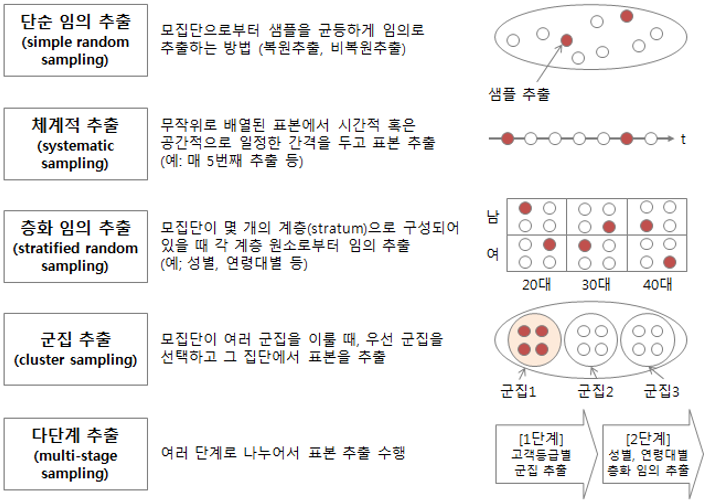